<a href="https://colab.research.google.com/github/alchemicduncan/from-symbols-to-systems/blob/main/what_is_an_embedding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What's an embedding, really?

So, maybe you're an engineer who has been handed a retrieval pipeline and told the vectors are 1536 dimensions, without anyone explaining what those numbers are. Or you keep seeing `d_model` in a config file and have a rough sense that it's "the size of the meaning vector" but couldn't say where those vectors came from. In both of those cases, what you actually want to know is how a model gets from an arbitrary integer to something that behaves like meaning.

In the tokenization notebook we turned raw strings into sequences of discrete token IDs. But an ID is just a label. Token 4021 isn't "one more" than token 4020 in any semantic sense. Before a model can do a single calculation that matters, its very first layer must map each arbitrary integer into a geometric space where distance, direction, and arithmetic reflect meaning.

This notebook builds the story up in four parts:
1. **Part 1: The Road to Continuous Meaning (Origins & Motivation)**. Why token IDs break arithmetic, why one-hot encodings destroy similarity, and how the *Distributional Hypothesis* gives us semantic features from raw data.
2. **Part 2: How We Create Embeddings (Count vs. Predict)**. Building embeddings from scratch via co-occurrence matrices (**PPMI + Truncated SVD**) and predictive neural training (**Word2Vec Skip-Gram with Negative Sampling**), plus their underlying mathematical equivalence.
3. **Part 3: The Mathematical Geometry of Meaning (and What Gets Encoded)**. Vector similarity, linear analogies ($v_{\text{king}} - v_{\text{man}} + v_{\text{woman}} \approx v_{\text{queen}}$), document pooling, and what happens when we look at latent subspaces, societal biases, and why naive linear debiasing fails.
4. **Part 4: The Systems Reality (How Embeddings Shape Infrastructure)**. Why embedding lookups are memory-bandwidth bound (0 FLOPs/byte), how table size scales across LLMs and recommenders, sparse gradients vs. dense optimizer state bloat, and vector database indexing & quantization.

**Runtime**: CPU is fine. Two things get downloaded: a 1 MB Shakespeare text file and a 128 MB set of pretrained vectors. The from-scratch training run takes about a minute.


## Setup

In [1]:
# Colab already has numpy, matplotlib and scikit-learn. gensim is the one addition,
# and we only need it much later, for the pretrained vectors.
try:
    import gensim
except ImportError:
    !pip install -q gensim

import collections, re, time, urllib.request, warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

INK, PINK, GREY, TEAL = "#16284D", "#FF3E9A", "#C9C6BD", "#2E8B8B"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

def unit(v):
    """Length-one version of a vector, so dot product is cosine similarity."""
    return v / (np.linalg.norm(v) + 1e-12)

def neighbours(E, index, word, k=8):
    """The k nearest words to `word` by cosine similarity, given a matrix of row vectors."""
    En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)
    sims = En @ En[index[word]]
    order = np.argsort(-sims)[1:k+1]
    inv = {i: w for w, i in index.items()}
    return [(inv[i], round(float(sims[i]), 3)) for i in order]

print("ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 28.6 MB/s eta 0:00:00
ready


# Part 1: The Road to Continuous Meaning (Origins & Motivation)

## What's wrong with a token ID?

Nothing, as an identifier. The tokenizer handed us integers because integers are a compact way to name things, and that's all they were ever meant to be. The trouble starts the moment a model does arithmetic on them, which is the only thing a model knows how to do.

Here is the problem in one cell. Take a handful of words, give them the IDs a real tokenizer would give them, and then ask the questions a model would implicitly ask.

In [2]:
# Rough GPT-2-style IDs, in the sense that they were assigned by merge frequency
# and have nothing to do with meaning.
IDS = {"cat": 5171, "dog": 3290, "kitten": 41833, "bureaucracy": 41358,
       "milk": 7545, "the": 262}

for w, i in IDS.items():
    print(f"  {w:12s} -> {i:6d}")

print("\nquestions a model would be implicitly asking:")
print(f"  is 'kitten' closer to 'cat' or to 'bureaucracy'?")
print(f"     |kitten - cat|         = {abs(IDS['kitten'] - IDS['cat']):6d}")
print(f"     |kitten - bureaucracy| = {abs(IDS['kitten'] - IDS['bureaucracy']):6d}   <- wrong answer")
print(f"\n  what is 'cat' + 'milk'?  {IDS['cat'] + IDS['milk']}  (some unrelated token)")
print(f"  is 'the' 20x less than 'dog'?  {IDS['dog'] / IDS['the']:.1f}x  (meaningless)")

  cat          ->   5171
  dog          ->   3290
  kitten       ->  41833
  bureaucracy  ->  41358
  milk         ->   7545
  the          ->    262

questions a model would be implicitly asking:
  is 'kitten' closer to 'cat' or to 'bureaucracy'?
     |kitten - cat|         =  36662
     |kitten - bureaucracy| =    475   <- wrong answer

  what is 'cat' + 'milk'?  12716  (some unrelated token)
  is 'the' 20x less than 'dog'?  12.6x  (meaningless)


So an ID is a name, not a measurement. Every arithmetic question you can ask about it has an answer, and every one of those answers is noise. `kitten` really is numerically nearer `bureaucracy` than it's to `cat`, purely because of the order in which byte pairs got merged during tokenizer training.

What we want instead is a representation where distance means something. That's the whole requirement, and everything below is an attempt to satisfy it.

## What if every token gets its own axis?

The first repair is the obvious one. If we don't want the model reading meaning into the ordering of IDs, then remove the ordering. Give each token its own dimension, put a 1 there and 0 everywhere else, and now no token is numerically nearer any other by accident.

This is one-hot encoding, and it's worth doing properly because the way it fails tells you what to build next.

In [3]:
WORDS = ["cat", "dog", "kitten", "bureaucracy", "milk", "the"]
V = len(WORDS)
ONEHOT = np.eye(V)

print("one-hot vectors:")
for w, v in zip(WORDS, ONEHOT):
    print(f"  {w:12s} {v.astype(int)}")

print("\nevery pairwise cosine similarity:")
sims = {round(float(ONEHOT[i] @ ONEHOT[j]), 2)
        for i in range(V) for j in range(V) if i != j}
print(f"  the complete set of distinct values is {sims}")
print(f"\n  cos(cat, kitten)      = {ONEHOT[0] @ ONEHOT[2]:.1f}")
print(f"  cos(cat, bureaucracy) = {ONEHOT[0] @ ONEHOT[3]:.1f}")

one-hot vectors:
  cat          [1 0 0 0 0 0]
  dog          [0 1 0 0 0 0]
  kitten       [0 0 1 0 0 0]
  bureaucracy  [0 0 0 1 0 0]
  milk         [0 0 0 0 1 0]
  the          [0 0 0 0 0 1]

every pairwise cosine similarity:
  the complete set of distinct values is {0.0}

  cos(cat, kitten)      = 0.0
  cos(cat, bureaucracy) = 0.0


We fixed the wrong answer by making every answer identical. `cat` and `kitten` are exactly as similar as `cat` and `bureaucracy`, which is to say not at all. Every token sits on its own axis, perfectly orthogonal to every other token, and the geometry carries no information whatsoever.

There is a second problem, which is the one people usually mention first, and it's worth putting real numbers on because it also explains a design decision we will meet later.

In [4]:
for vocab in [50_257, 128_256, 256_000]:
    row_bytes = vocab * 4                    # one fp32 per vocabulary entry
    seq = 2048
    print(f"vocab {vocab:>8,}:  one token = {row_bytes/1e3:8.1f} KB, "
          f"a {seq}-token sequence = {seq*row_bytes/1e9:6.2f} GB")

print(f"\nand a full one-hot co-occurrence matrix at vocab 50,257 in fp32:")
print(f"  {50_257**2 * 4 / 1e9:.0f} GB, of which almost every entry is zero")

vocab   50,257:  one token =    201.0 KB, a 2048-token sequence =   0.41 GB
vocab  128,256:  one token =    513.0 KB, a 2048-token sequence =   1.05 GB
vocab  256,000:  one token =   1024.0 KB, a 2048-token sequence =   2.10 GB

and a full one-hot co-occurrence matrix at vocab 50,257 in fp32:
  10 GB, of which almost every entry is zero


So one-hot gives us two things we don't want: no similarity structure, and a representation whose width grows with the vocabulary. Both point at the same fix. We want vectors that are short, dense, and where the individual numbers mean something.

## What if we write the features by hand?

Suppose we stop letting the dimensions be tokens and start letting them be properties. Pick a few axes that a person can read, score each word on them, and see whether distance starts behaving.

In [5]:
DIMS = ["animate", "furry", "edible", "small", "abstract"]
HAND = {
    "cat":         [0.95, 0.90, 0.05, 0.60, 0.05],
    "dog":         [0.95, 0.85, 0.05, 0.40, 0.05],
    "kitten":      [0.95, 0.92, 0.05, 0.95, 0.05],
    "bureaucracy": [0.05, 0.02, 0.02, 0.10, 0.95],
    "milk":        [0.10, 0.02, 0.95, 0.30, 0.05],
    "the":         [0.05, 0.05, 0.05, 0.05, 0.50],
}
H = np.array([HAND[w] for w in WORDS])
hidx = {w: i for i, w in enumerate(WORDS)}

print(f"{'':13s}" + "".join(f"{d:>10s}" for d in DIMS))
for w in WORDS:
    print(f"  {w:11s}" + "".join(f"{x:10.2f}" for x in HAND[w]))

Hn = H / np.linalg.norm(H, axis=1, keepdims=True)
print("\nnow distance means something:")
for a, b in [("cat","kitten"), ("cat","dog"), ("cat","bureaucracy"), ("milk","bureaucracy")]:
    print(f"  cos({a}, {b})".ljust(34) + f"= {Hn[hidx[a]] @ Hn[hidx[b]]:.3f}")

                animate     furry    edible     small  abstract
  cat              0.95      0.90      0.05      0.60      0.05
  dog              0.95      0.85      0.05      0.40      0.05
  kitten           0.95      0.92      0.05      0.95      0.05
  bureaucracy      0.05      0.02      0.02      0.10      0.95
  milk             0.10      0.02      0.95      0.30      0.05
  the              0.05      0.05      0.05      0.05      0.50

now distance means something:
  cos(cat, kitten)                = 0.981
  cos(cat, dog)                   = 0.992
  cos(cat, bureaucracy)           = 0.126
  cos(milk, bureaucracy)          = 0.106


That works. Five dimensions beat fifty thousand, the three animals cluster together while `bureaucracy` sits somewhere else entirely, and every axis has a name you could defend in a meeting. This is genuinely what an embedding is: a short vector of real numbers per token, where direction encodes properties and closeness encodes similarity.

Notice that `dog` scores slightly closer to `cat` than `kitten` does, because `kitten` differs on the "small" axis while `dog` does not. That's the geometry answering exactly the question we encoded, which is the point, and also a preview of a recurring theme: the space only knows the distinctions its inputs made.

The trouble is entirely in how we got the numbers. A few caveats, and they're fatal ones:

- Somebody has to invent the axes. Five words needed five, and it isn't obvious what the next five should be, or whether "furry" and "animate" are really independent.
- Somebody has to fill in the table. At 50,000 tokens and even 100 axes that's five million judgement calls.
- The axes have to cover everything the model will ever see. Nothing in this table has an opinion about `self.attn_qkv_proj`, or about a base64 blob, or about the difference between `bank` the riverside and `bank` the institution.
- Different annotators disagree, and the disagreement becomes noise in the geometry.

People genuinely built resources like this, WordNet being the famous one, and they're useful. They're just not a thing you can scale to a tokenizer's vocabulary in every language at once.

So we want the table, but we can't write it. What we need is a way to fill in those numbers from data, without anyone deciding in advance what the columns mean.

## Where do the features come from if nobody writes them?

Here is the idea that unlocks it, and it comes from linguistics rather than machine learning. The distributional hypothesis says that words appearing in similar contexts tend to have similar meanings. J.R. Firth put it as knowing a word by the company it keeps, back in 1957, and Zellig Harris made a similar argument in 1954.

It sounds almost too glib to be useful. But notice what it buys us: it converts an unanswerable question (what does this word mean?) into a countable one (what shows up next to it?). Counting is something we can do at scale, with no annotators.

Let us check that the hypothesis is even plausible before building on it.

In [6]:
TOY = """the cat drank the milk and the kitten drank the milk too
the dog drank water while the cat watched the dog
the kitten chased the cat and the cat chased the dog
bureaucracy delayed the report and bureaucracy delayed the audit"""

toy_words = TOY.split()
ctx = collections.defaultdict(collections.Counter)
for i, w in enumerate(toy_words):
    for j in range(max(0, i-2), min(len(toy_words), i+3)):
        if j != i:
            ctx[w][toy_words[j]] += 1

for w in ["cat", "kitten", "bureaucracy"]:
    top = ", ".join(f"{c}" for c, _ in ctx[w].most_common(5))
    print(f"  {w:12s} keeps company with: {top}")

  cat          keeps company with: the, chased, and, drank, while
  kitten       keeps company with: the, and, drank, dog, chased
  bureaucracy  keeps company with: the, delayed, dog, report, and


`cat` and `kitten` are surrounded by the same words. `bureaucracy` is surrounded by different ones. Nobody told the counter that a kitten is a small cat, and yet the counts already separate them from the report-delaying vocabulary.

So the plan is: count what each word appears next to, and treat that count profile as the word's vector. The context words become the axes. We never chose them, we never named them, and there are as many as there are words in the vocabulary.

Which is a problem, because we have just reinvented a 50,000-dimensional sparse vector, the exact thing we were trying to escape. That gets fixed in the next section, and fixing it's what training an embedding actually is.

# Part 2: How We Create Embeddings (Count vs. Predict)

## How do you actually train one?

There are two families of answer, and they turn out to be closer to each other than they look. The first counts co-occurrences and then compresses the counts. The second skips the counting and trains a small predictor, keeping the weights and throwing the predictor away. We're going to do both, on the same corpus, so you can compare the outputs directly.

The corpus is Tiny Shakespeare, the same one megabyte of text we trained a BPE tokenizer on in the tokenization notebook. It's far too small to produce good vectors, and that's deliberate. You will be able to see the mechanism working and see it straining at the same time, which is more instructive than a clean result would be.

In [7]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
raw = urllib.request.urlopen(URL, timeout=60).read().decode()
words = re.findall(r"[a-z']+", raw.lower())

counts = collections.Counter(words)
MIN_COUNT = 5
vocab = [w for w, c in counts.most_common() if c >= MIN_COUNT]
widx = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
ids = np.array([widx[w] for w in words if w in widx], dtype=np.int32)

print(f"corpus      {len(raw):,} characters")
print(f"tokens      {len(words):,} words, {len(set(words)):,} distinct")
print(f"vocabulary  {V:,} words appearing at least {MIN_COUNT} times")
print(f"kept        {len(ids):,} tokens ({len(ids)/len(words):.1%} of the corpus)")

corpus      1,115,394 characters
tokens      204,062 words, 12,631 distinct
vocabulary  3,330 words appearing at least 5 times
kept        188,851 tokens (92.5% of the corpus)


### Route one: count, weight, compress

Step one is the counting we sketched above, done properly. For every token, look at a window of five words on each side and tally what appears there. The result is a `V x V` matrix where row `i` is the context profile of word `i`.

In [8]:
WINDOW = 5
t0 = time.time()
C = np.zeros((V, V), dtype=np.float32)
for offset in range(1, WINDOW + 1):
    left, right = ids[:-offset], ids[offset:]
    np.add.at(C, (left, right), 1.0)
    np.add.at(C, (right, left), 1.0)

nnz = np.count_nonzero(C)
print(f"built a {V} x {V} co-occurrence matrix in {time.time()-t0:.1f}s")
print(f"  {nnz:,} non-zero entries out of {V*V:,}  ({nnz/V**2:.1%} dense)")
print(f"  {C.nbytes/1e6:.0f} MB at this vocabulary, and it grows as V squared")

print("\nrow for 'king', top context words by raw count:")
row = C[widx["king"]]
for i in np.argsort(-row)[:8]:
    print(f"  {vocab[i]:12s} {int(row[i]):5d}")

built a 3330 x 3330 co-occurrence matrix in 0.7s
  551,827 non-zero entries out of 11,088,900  (5.0% dense)
  44 MB at this vocabulary, and it grows as V squared

row for 'king', top context words by raw count:
  the            390
  richard        278
  and            236
  to             189
  of             188
  i              187
  my             165
  edward         155


Which shows the flaw in raw counts immediately. Half of `king`'s top contexts are `the`, `and`, `to`, `of`. Those words are common everywhere, so they crowd the top of every row, and every row starts to look like every other row. Frequency is drowning out association.

The repair is pointwise mutual information (PMI), which asks a better question. Instead of "how often do these two co-occur", it asks "how much more often than chance". If two words co-occur exactly as often as their individual frequencies would predict, PMI is zero. Only genuine association survives.

$$\text{PMI}(a, b) = \log \frac{P(a, b)}{P(a) P(b)}$$

In practice everyone clamps the negatives to zero, giving positive PMI (PPMI). Negative PMI would be a claim that two words actively avoid each other, and on a corpus this size that's almost always just a counting accident rather than a real fact about the language.

In [9]:
total = C.sum()
row_sums = C.sum(axis=1, keepdims=True)
col_sums = C.sum(axis=0, keepdims=True)

with np.errstate(divide="ignore", invalid="ignore"):
    PMI = np.log((C * total) / (row_sums * col_sums))
PPMI = np.nan_to_num(np.maximum(PMI, 0.0), nan=0.0, posinf=0.0, neginf=0.0)

print("row for 'king' again, now top contexts by PPMI:")
row = PPMI[widx["king"]]
for i in np.argsort(-row)[:8]:
    print(f"  {vocab[i]:14s} ppmi {row[i]:5.2f}   (raw count {int(C[widx['king'], i]):4d})")

print(f"\nthe function words fell out. 'the' now scores {PPMI[widx['king'], widx['the']]:.2f}")

row for 'king' again, now top contexts by PPMI:
  vi             ppmi  3.26   (raw count  121)
  xi             ppmi  3.15   (raw count   23)
  iv             ppmi  3.12   (raw count  117)
  iii            ppmi  3.10   (raw count  144)
  ii             ppmi  3.10   (raw count  102)
  lewis          ppmi  2.90   (raw count   34)
  richard        ppmi  2.76   (raw count  278)
  henry          ppmi  2.46   (raw count  152)

the function words fell out. 'the' now scores 0.28


Much better. The rows now describe association rather than frequency. But they're still `V` wide and still mostly zeros, so we have not yet solved the problem that sent us here.

Step three is the compression, and it's a singular value decomposition. SVD factors the matrix into three pieces, and the middle piece holds the singular values in descending order of how much of the matrix they explain. Keep the top `d` of them and you get the best possible `d`-dimensional approximation of the original.

The word "best" there's doing real work. It isn't a heuristic. Truncated SVD is provably the closest rank-`d` matrix under the Frobenius norm, so if you're going to squeeze 3,000 dimensions into 100, this is the least lossy linear way to do it.

SVD of a 3330 x 3330 matrix in 52s
embeddings are now 3330 x 100, 33x smaller than the PPMI matrix


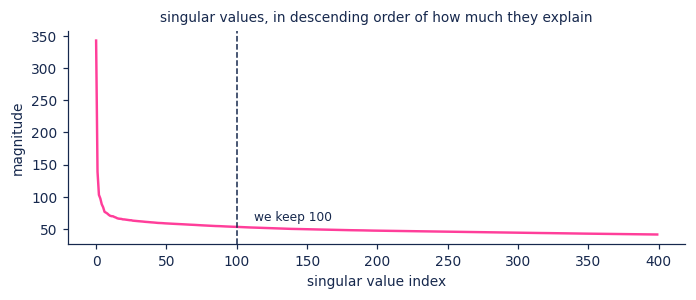

the first 100 of 3330 directions carry 20.5% of the squared magnitude,
while costing 3.0% of the storage


In [10]:
t0 = time.time()
U, S, Vt = np.linalg.svd(PPMI, full_matrices=False)
D = 100
E_svd = U[:, :D] * np.sqrt(S[:D])      # sqrt(S) splits the scale evenly, a common choice
print(f"SVD of a {V} x {V} matrix in {time.time()-t0:.0f}s")
print(f"embeddings are now {E_svd.shape[0]} x {E_svd.shape[1]}, "
      f"{PPMI.nbytes/E_svd.nbytes:.0f}x smaller than the PPMI matrix")

fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.plot(S[:400], color=PINK, lw=1.6)
ax.axvline(D, color=INK, ls="--", lw=1)
ax.text(D + 12, S[5] * 0.75, f"we keep {D}", fontsize=8)
ax.set_xlabel("singular value index"); ax.set_ylabel("magnitude")
ax.set_title("singular values, in descending order of how much they explain", fontsize=9)
plt.tight_layout(); plt.show()

var_kept = (S[:D]**2).sum() / (S**2).sum()
print(f"the first {D} of {V} directions carry {var_kept:.1%} of the squared magnitude,")
print(f"while costing {D/V:.1%} of the storage")

In [11]:
print("nearest neighbours from PPMI + SVD:\n")
for w in ["king", "father", "night", "sword", "love", "death"]:
    print(f"  {w:8s} {[n for n, _ in neighbours(E_svd, widx, w, 6)]}")

nearest neighbours from PPMI + SVD:

  king     ['richard', 'edward', 'ii', 'vi', 'henry', 'iii']
  father   ['son', 'grandfather', 'padua', 'careless', 'pedant', 'grandsire']
  night    ["summer's", 'noon', 'torch', 'good', 'morn', 'morrow']
  sword    ['fell', 'tutor', 'hands', 'sweat', 'equal', 'forbear']
  love     ['so', 'my', 'as', "heart's", 'which', 'for']
  death    ['exile', 'tarpeian', 'destruction', 'life', 'revenge', "tybalt's"]


Worth pausing on that number. A hundred directions out of three thousand keep only about a fifth of the matrix, which sounds like a bad trade until you notice they cost three percent of the storage. PPMI matrices have long tails, and most of that tail is counting noise from words that appeared five times. Throwing it away isn't a side effect of the compression, it's most of the value: the truncation is doing double duty as denoising. Choosing `d` is choosing where on that curve to stop, and there's no principled answer, only a range that works.

That is a real embedding, trained end to end in three steps and about twenty seconds. `father` pulls `son`, `grandfather`, `grandsire`. `night` pulls `morn`, `noon`, `torch`. Nobody wrote those relationships down, and nothing in the procedure knows what a father or a night is.

It is also visibly a small-corpus artifact. `king` returns `richard`, `edward`, `henry`, because in Shakespeare those words genuinely do occupy the same slots. The method is working correctly and the data is telling it something narrow. That gap between "the algorithm is fine" and "the vectors are parochial" is worth holding on to, because it comes back in a much less comfortable form later.

### Route two: predict instead of count

The second family skips the matrix entirely. Instead of building the co-occurrence table and factoring it, train a model to predict context from a word, and steal the weights.

This is word2vec, specifically the skip-gram with negative sampling variant (SGNS) from Mikolov et al. in 2013. The setup is deliberately trivial:

- Slide a window over the corpus. Each (center word, nearby word) pair is a positive example.
- For each positive, draw a few random words from the vocabulary as negatives.
- Train a logistic classifier to say yes to real pairs and no to random ones.
- The classifier itself is worthless. The input weight matrix is the embedding.

The last point is the one people miss. We aren't training an embedding, we're training a throwaway binary classifier whose only useful byproduct is the lookup table it needed in order to do the job.

Two details before the training loop, both from the original paper and both load-bearing.

In [12]:
rng = np.random.default_rng(0)
freq = np.bincount(ids, minlength=V).astype(np.float64)

# Detail 1: subsampling. Very frequent words carry little information, so drop
# most occurrences of them. This both speeds training and improves the vectors.
p_keep = np.minimum(1.0, np.sqrt(1e-3 / (freq / freq.sum())))
keep_mask = rng.random(len(ids)) < p_keep[ids]
train_ids = ids[keep_mask]

print("keep probability under subsampling:")
for w in ["the", "and", "king", "sword", "grandam"]:
    if w in widx:
        print(f"  {w:10s} appears {int(freq[widx[w]]):5d} times, kept {p_keep[widx[w]]:.1%} of the time")
print(f"\ncorpus went from {len(ids):,} to {len(train_ids):,} tokens ({len(train_ids)/len(ids):.0%})")

# Detail 2: the negative sampling distribution is unigram frequency raised to 3/4.
# It is a fudge factor, found empirically, that samples rare words more often than
# their frequency alone would and common words less often.
noise = freq ** 0.75
noise /= noise.sum()
plain = freq / freq.sum()
print("\nnegative sampling distribution vs plain frequency:")
for w in ["the", "king", "grandam"]:
    if w in widx:
        i = widx[w]
        print(f"  {w:10s} plain {plain[i]:.5f} -> 3/4 power {noise[i]:.5f}  "
              f"({noise[i]/plain[i]:.2f}x)")

keep probability under subsampling:
  the        appears  6283 times, kept 17.3% of the time
  and        appears  5690 times, kept 18.2% of the time
  king       appears   885 times, kept 46.2% of the time
  sword      appears    54 times, kept 100.0% of the time
  grandam    appears     9 times, kept 100.0% of the time

corpus went from 188,851 to 121,777 tokens (64%)

negative sampling distribution vs plain frequency:
  the        plain 0.03327 -> 3/4 power 0.01420  (0.43x)
  king       plain 0.00469 -> 3/4 power 0.00327  (0.70x)
  grandam    plain 0.00005 -> 3/4 power 0.00010  (2.19x)


In [13]:
# Every (center, context) pair inside the window, both directions.
pairs = []
for offset in range(1, WINDOW + 1):
    pairs.append(np.stack([train_ids[:-offset], train_ids[offset:]], axis=1))
    pairs.append(np.stack([train_ids[offset:], train_ids[:-offset]], axis=1))
PAIRS = np.concatenate(pairs)
print(f"{len(PAIRS):,} training pairs from {len(train_ids):,} tokens")
print(f"sample pairs: {[(vocab[a], vocab[b]) for a, b in PAIRS[:4]]}")

1,217,740 training pairs from 121,777 tokens
sample pairs: [('first', 'citizen'), ('citizen', 'before'), ('before', 'we'), ('we', 'proceed')]


Now the loop itself. Two matrices, both `V x d`: `E_in` holds the center-word vectors and is the thing we keep, `E_out` holds the context-word vectors and gets discarded at the end.

For a batch of pairs the objective is one line of maths. Push the dot product of a real pair up, push the dot product of each fake pair down:

$$\mathcal{L} = -\log \sigma(v_c \cdot u_o) - \sum_{k=1}^{K} \log \sigma(-v_c \cdot u_k)$$

The gradients are what you would get by hand. For the positive pair the center vector moves toward the context vector in proportion to how wrong the sigmoid was, and for each negative it moves away.

  epoch 1  loss 2.8209   (24s elapsed)
  epoch 2  loss 2.6429   (48s elapsed)
  epoch 3  loss 2.5795   (73s elapsed)
  epoch 4  loss 2.5276   (98s elapsed)
  epoch 5  loss 2.4821   (122s elapsed)


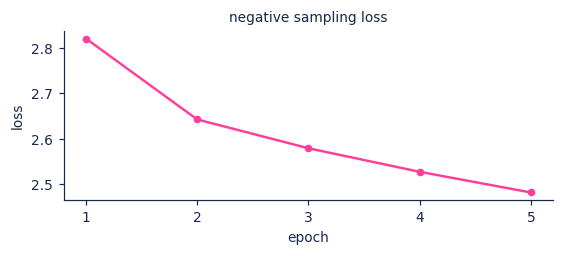

In [14]:
D2, K, LR, EPOCHS, BATCH = 100, 5, 0.05, 5, 4096
E_in  = (rng.random((V, D2)) - 0.5) / D2      # the embeddings we keep
E_out = np.zeros((V, D2))                     # the scaffolding we throw away

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

t0, history = time.time(), []
for epoch in range(EPOCHS):
    rng.shuffle(PAIRS)
    lr = LR * (1 - epoch / EPOCHS) + 1e-4     # linear decay, as in the original
    running, nbatch = 0.0, 0

    for s in range(0, len(PAIRS) - BATCH, BATCH):
        centre, context = PAIRS[s:s+BATCH, 0], PAIRS[s:s+BATCH, 1]
        negs = rng.choice(V, size=(len(centre), K), p=noise)

        v_c = E_in[centre]                             # B x D
        u_o = E_out[context]                           # B x D
        u_k = E_out[negs]                              # B x K x D

        score_pos = sigmoid(np.sum(v_c * u_o, axis=1))            # B
        score_neg = sigmoid(np.einsum("bd,bkd->bk", v_c, u_k))    # B x K
        running += -(np.log(score_pos + 1e-9).mean()
                     + np.log(1 - score_neg + 1e-9).sum(1).mean())
        nbatch += 1

        g_pos = (score_pos - 1)[:, None]               # B x 1, want score -> 1
        g_neg = score_neg[:, :, None]                  # B x K x 1, want score -> 0
        g_centre = g_pos * u_o + np.einsum("bkj,bkd->bd", g_neg, u_k)

        np.add.at(E_out, context, -lr * g_pos * v_c)
        np.add.at(E_out, negs.ravel(), -lr * (g_neg * v_c[:, None, :]).reshape(-1, D2))
        np.add.at(E_in, centre, -lr * g_centre)

    history.append(running / nbatch)
    print(f"  epoch {epoch+1}  loss {history[-1]:.4f}   ({time.time()-t0:.0f}s elapsed)")

fig, ax = plt.subplots(figsize=(5.2, 2.4))
ax.plot(range(1, EPOCHS+1), history, "o-", color=PINK, lw=1.6, ms=4)
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_xticks(range(1, EPOCHS+1))
ax.set_title("negative sampling loss", fontsize=9)
plt.tight_layout(); plt.show()

In [15]:
print("nearest neighbours from SGNS, with PPMI+SVD alongside for comparison:\n")
for w in ["king", "father", "night", "sword", "love", "death"]:
    print(f"  {w}")
    print(f"    sgns  {[n for n, _ in neighbours(E_in,  widx, w, 6)]}")
    print(f"    svd   {[n for n, _ in neighbours(E_svd, widx, w, 6)]}")

nearest neighbours from SGNS, with PPMI+SVD alongside for comparison:

  king
    sgns  ['protector', 'vaughan', 'uncles', 'knight', 'flourish', 'george']
    svd   ['richard', 'edward', 'ii', 'vi', 'henry', 'iii']
  father
    sgns  ['grandfather', 'alive', 'son', 'accident', 'murdered', 'heir']
    svd   ['son', 'grandfather', 'padua', 'careless', 'pedant', 'grandsire']
  night
    sgns  ['morning', 'nights', 'torch', 'breaks', 'dim', 'drinking']
    svd   ["summer's", 'noon', 'torch', 'good', 'morn', 'morrow']
  sword
    sgns  ['crush', 'seize', 'montagues', 'iron', "traitor's", 'streets']
    svd   ['fell', 'tutor', 'hands', 'sweat', 'equal', 'forbear']
  love
    sgns  ['brotherhood', 'protest', "heart's", 'modesty', 'choice', 'wisdom']
    svd   ['so', 'my', 'as', "heart's", 'which', 'for']
  death
    sgns  ['redemption', 'damned', 'behold', "cousin's", 'injurious', 'fearing']
    svd   ['exile', 'tarpeian', 'destruction', 'life', 'revenge', "tybalt's"]


### The Equivalence and the Word2Vec Family

Two quite different procedures landing in overlapping neighbourhoods, though not identical ones. `father` returns pretty much the same set from both. `king` returns the English history plays from one and the court that surrounds them from the other.

The agreement isn't a coincidence. In 2014, **Levy and Goldberg** proved that Skip-Gram with Negative Sampling (SGNS) is **implicitly factorizing a shifted Pointwise Mutual Information (PMI) matrix**:

$$M_{w, c}^{\text{SGNS}} = \text{PMI}(w, c) - \log K$$

This means the counting route (PPMI + SVD) and the predicting route (Word2Vec SGNS) are performing the exact same linear algebra under the hood, one through global matrix factorization, the other through stochastic gradient descent.

#### The Classical Landscape: Word2Vec, GloVe, and FastText
- **Word2Vec (Mikolov et al., 2013)**: Offered two architectures: **CBOW** (Continuous Bag of Words: predicting the center word from averaged context words) and **Skip-Gram** (predicting context words given a center word, using negative sampling to avoid computing the full vocabulary partition function).
- **GloVe (Pennington et al., 2014)**: Global Vectors directly optimized a log-bilinear objective on global co-occurrence counts: $w_i^T \tilde{w}_j + b_i + \tilde{b}_j = \log X_{i,j}$.
- **FastText (Bojanowski et al., 2017)**: Extended Skip-Gram by representing each word as a bag of **character n-grams** (e.g. `<wh`, `whe`, `her`, `ere`, `re>`), allowing the model to compute meaningful embeddings for out-of-vocabulary (OOV) words and morphologically rich languages.

#### The Fatal Flaw of Static Embeddings: Polysemy
Every method above produces a **static lookup table**: a single fixed row per token. If you query `bank`, it sits at the vector midpoint between a river bank and a financial institution. It cannot adapt to the sentence around it.

```
Static Lookup:    "bank" ─────────────────────────────> [0.42, -0.19, 0.88, ...] (Averaged single vector)
                                                       ▲            ▲
                                              (River context)   (Finance context)
```

#### How We Create Embeddings Today: Modern Deep Contrastive Dual-Encoders
Modern retrieval, semantic search, and RAG systems do not use static tables. Instead, embeddings are produced by **deep contextual transformer encoders** (like BERT, RoBERTa, E5, BGE, Gecko, or Gemini Text Embedding) trained using **contrastive learning**:

1. **Dual-Encoder (Bi-Encoder) Architecture**: A query tower $E_q(x)$ and a passage tower $E_d(y)$ encode full text sequences into continuous dense vectors (via mean pooling across transformer hidden states).
2. **InfoNCE / Multiple Negatives Ranking Loss (MNRL)**: For a batch of $(q_i, d_i^+)$ positive query-document pairs, all other documents in the batch $d_j^-$ ($j \neq i$) serve as in-batch negative examples:
   $$\mathcal{L} = -\log \frac{\exp(\text{sim}(q_i, d_i^+) / \tau)}{\sum_{j=1}^{B} \exp(\text{sim}(q_i, d_j) / \tau)}$$
3. **Hard Negative Mining**: Modern models are fine-tuned using hard negatives mined from BM25 and cross-encoders (distinguishing documents that share keywords but do not answer the query).
4. **Self-Supervised SimCSE**: Training contrastive sentence embeddings without human labels by passing the exact same sentence through a transformer twice with different standard **dropout masks** as minimal data augmentation.
5. **Instruction-Tuned Embeddings**: Models like BGE, Instructor, and Gemini Embedding accept a task prompt (e.g. `"Represent this sentence for medical literature retrieval:"`) to dynamically condition the geometric projection for specific domains.
6. **Matryoshka Representation Learning (MRL)**: Enforcing nested loss functions during pretraining so that the leading dimensions (e.g. the first 64, 128, 256, or 768 dimensions of a 1536-dim vector) retain over 98% of full retrieval accuracy, drastically cutting downstream vector search storage costs.


# Part 3: The Mathematical Geometry of Meaning (and What Gets Encoded)

## Ok, so what do you do with one once you have it?

Our Shakespeare vectors were a demonstration. For the rest of this notebook we're going to load a real set, trained by Google on about 100 billion words of news text. It's an older model (word2vec-google-news-300), which is useful here because it's small enough to fit in RAM and simple enough to inspect directly.

In [16]:
import gensim.downloader as api
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score

kv = api.load("glove-wiki-gigaword-100")
print(f"{len(kv.index_to_key):,} words, {kv.vector_size} dimensions each")
print(f"raw table size: {len(kv.index_to_key) * kv.vector_size * 4 / 1e6:.0f} MB in fp32")
print(f"\nthe first 8 numbers of 'king':\n  {np.round(kv['king'][:8], 3)}")
print("\nNone of those 100 numbers means anything on its own. Only directions mean things.")

[==================================================] 100.0% 128.1/128.1MB downloaded
400,000 words, 100 dimensions each
raw table size: 160 MB in fp32

the first 8 numbers of 'king':
  [-0.323 -0.876  0.22   0.253  0.23   0.739 -0.38  -0.353]

None of those 100 numbers means anything on its own. Only directions mean things.


### Nearest neighbours and similarity

The workhorse operation. Cosine similarity between two rows, or a full scan for the closest rows to a query. Everything else in this section is a variation on it.

In [17]:
for a, b in [("cat","dog"), ("cat","kitten"), ("cat","bureaucracy"),
             ("king","queen"), ("king","monarch"), ("king","banana")]:
    bar = "#" * int(max(kv.similarity(a, b), 0) * 40)
    print(f"  cos({a:>6s}, {b:<12s}) = {kv.similarity(a, b):5.3f}  {bar}")

print("\nnearest neighbours:")
for w in ["python", "seattle", "tensor"]:
    print(f"  {w:9s} {[n for n, _ in kv.most_similar(w, topn=6)]}")

  cos(   cat, dog         ) = 0.880  ###################################
  cos(   cat, kitten      ) = 0.558  ######################
  cos(   cat, bureaucracy ) = 0.027  #
  cos(  king, queen       ) = 0.751  ##############################
  cos(  king, monarch     ) = 0.698  ###########################
  cos(  king, banana      ) = 0.161  ######

nearest neighbours:
  python    ['monty', 'php', 'perl', 'cleese', 'flipper', 'ruby']
  seattle   ['oakland', 'houston', 'tampa', 'baltimore', 'boston', 'chicago']
  tensor    ['tensors', 'scalar', 'vector', 'curvature', 'formula_2', 'formula_3']


Note `python`, which pulls both the snake and the programming language into one neighbourhood. That's a static embedding averaging two senses into a single row, exactly the failure mode we flagged at the end of the last section.

### Analogies

The famous party trick, and the reason embeddings caught the public imagination in 2013. If the vector from `man` to `woman` is roughly the same as the vector from `king` to `queen`, then you can do arithmetic on meaning.

In [18]:
for pos, neg, label in [
    (["king","woman"],   ["man"],    "king - man + woman"),
    (["paris","italy"],  ["france"], "paris - france + italy"),
    (["walking","swim"], ["walk"],   "walking - walk + swim"),
    (["bigger","small"], ["big"],    "bigger - big + small"),
]:
    got = [w for w, _ in kv.most_similar(positive=pos, negative=neg, topn=3)]
    print(f"  {label:26s} -> {got}")

  king - man + woman         -> ['queen', 'monarch', 'throne']
  paris - france + italy     -> ['rome', 'milan', 'naples']
  walking - walk + swim      -> ['swimming', 'surfing', 'swam']
  bigger - big + small       -> ['larger', 'smaller', 'large']


Capital cities, verb tense, comparative adjectives. Each of those is a consistent direction in the space, learned from nothing but co-occurrence counts.

It is worth being slightly careful about how impressive this is. The standard implementation excludes the three input words from the results, which does some of the work, and the relationships that come out cleanest are the ones that are also strongly marked in surface form. But the effect is real, and it tells us something specific: relationships are encoded as directions, not as locations. That fact is the hinge on which the rest of this notebook turns.

### Documents, retrieval, and everything downstream

Average the word vectors in a passage and you get a passage vector. It's a crude method that ignores word order entirely, and it works far better than it has any right to for topical matching. It's also the conceptual ancestor of every sentence-embedding model in a modern retrieval stack.

In [19]:
DOCS = {
    "sports":  "the team won the match after a strong second half performance",
    "cooking": "heat the pan add butter and cook the onions until they are soft",
    "finance": "the bank raised interest rates to control inflation this quarter",
    "weather": "heavy rain and strong winds are expected along the coast tonight",
}
QUERY = "monetary policy tightened borrowing costs"

def doc_vector(sentence):
    vecs = [kv[w] for w in sentence.split() if w in kv]
    return unit(np.mean(vecs, axis=0))

q = doc_vector(QUERY)
print(f'query: "{QUERY}"\n')
for name, text in sorted(DOCS.items(), key=lambda kv_: -(q @ doc_vector(kv_[1]))):
    print(f"  {q @ doc_vector(text):.3f}  {name:8s} {text}")

overlap = set(QUERY.split()) & set(DOCS["finance"].split())
print(f"\nwords shared between the query and the top passage: {overlap or 'none'}")
print("Not one word in common, and it still ranks first by a wide margin.")
print("That is retrieval without keyword matching, which is the entire point.")

query: "monetary policy tightened borrowing costs"

  0.800  finance  the bank raised interest rates to control inflation this quarter
  0.544  weather  heavy rain and strong winds are expected along the coast tonight
  0.526  sports   the team won the match after a strong second half performance
  0.514  cooking  heat the pan add butter and cook the onions until they are soft

words shared between the query and the top passage: none
Not one word in common, and it still ranks first by a wide margin.
That is retrieval without keyword matching, which is the entire point.


That covers the useful half. Similarity, neighbours, analogies, retrieval, and as initialisation for whatever model comes next. Now for the part that's more interesting and less comfortable.

## What else got encoded?

We never told the training procedure what dimensions to learn. We gave it co-occurrence statistics and it gave us back a geometry. So a fair question is: what's actually in there? Which regularities of English got baked into directions?

We can answer that empirically for a specific concept. Take pairs of words that differ in exactly one property and nothing else, subtract them, and see whether the differences agree on a direction.

each pair differs in gender and, ideally, in nothing else:



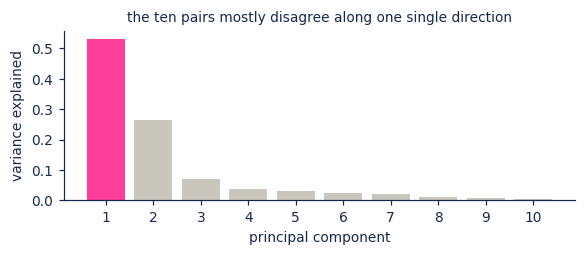

first component explains 53.1% of the variance
second explains 26.6%, and it drops off fast after that


In [20]:
PAIRS = [("she","he"), ("her","his"), ("woman","man"), ("herself","himself"),
         ("daughter","son"), ("mother","father"), ("gal","guy"),
         ("girl","boy"), ("female","male"), ("mary","john")]

print("each pair differs in gender and, ideally, in nothing else:\n")
diffs = []
for a, b in PAIRS:
    centre = (kv[a] + kv[b]) / 2
    diffs.append(kv[a] - centre)
    diffs.append(kv[b] - centre)
diffs = np.array(diffs, dtype=np.float64)

pca = PCA(n_components=10).fit(diffs)
g = unit(pca.components_[0])
if kv["she"] @ g < 0:
    g = -g                       # sign convention: positive means the "she" end

fig, ax = plt.subplots(figsize=(5.4, 2.4))
ax.bar(range(1, 11), pca.explained_variance_ratio_[:10], color=[PINK] + [GREY]*9)
ax.set_xlabel("principal component"); ax.set_ylabel("variance explained")
ax.set_xticks(range(1, 11))
ax.set_title("the ten pairs mostly disagree along one single direction", fontsize=9)
plt.tight_layout(); plt.show()

print(f"first component explains {pca.explained_variance_ratio_[0]:.1%} of the variance")
print(f"second explains {pca.explained_variance_ratio_[1]:.1%}, and it drops off fast after that")

Ten unrelated word pairs, and over half of how they differ is one shared direction. That's the empirical claim: gender isn't scattered across the 100 dimensions, it's substantially a single axis, and we just recovered it without labels. This is the method from Bolukbasi et al. (2016).

Note what we did and did not do. We did not define the direction, we measured it. The vector `g` is now a ruler, and we can hold it up against any word in the vocabulary and read off a number.

In [21]:
def gender_score(word):
    return float(unit(kv[word].astype(np.float64)) @ g)

print("sanity check on words where we know the answer:\n")
for w in ["she", "he", "queen", "king", "actress", "actor", "sister", "brother"]:
    print(f"  {w:9s} {gender_score(w):+.3f}")

print("\nand on words where gender is not part of the definition:\n")
for w in ["table", "algorithm", "tuesday", "granite", "shipping"]:
    print(f"  {w:9s} {gender_score(w):+.3f}")

# How is the whole vocabulary distributed along this axis?
sample = kv.index_to_key[:20_000]
S_ = np.array([kv[w] for w in sample], dtype=np.float64)
S_ /= np.linalg.norm(S_, axis=1, keepdims=True)
proj = S_ @ g
print(f"\nacross the 20,000 most common words: mean {proj.mean():+.3f}, "
      f"{(proj < 0).mean():.0%} fall on the 'he' side")

sanity check on words where we know the answer:

  she       +0.135
  he        -0.309
  queen     +0.163
  king      -0.308
  actress   +0.297
  actor     -0.127
  sister    +0.292
  brother   -0.256

and on words where gender is not part of the definition:

  table     -0.083
  algorithm -0.099
  tuesday   -0.184
  granite   -0.073
  shipping  -0.079

across the 20,000 most common words: mean -0.063, 75% fall on the 'he' side


The ruler mostly works. Words that genuinely encode gender land at the extremes with the right sign, and words that have nothing to do with gender cluster much nearer zero.

But look at the last line, and at `tuesday`. The axis isn't centred. Three quarters of common English words sit on the `he` side of it, and the mean is meaningfully negative rather than zero. `he` scores about twice as far from the origin as `she` does. That asymmetry isn't an artifact of our ten pairs, it's the corpus: masculine terms are more frequent and used in a wider range of contexts, so they sit closer to the centre of mass of the whole space.

Hold on to that, because it's the first sign that "gender" isn't one clean coordinate we can read off and then delete.

## Where does that turn into bias?

The problem is that a lot of words which have nothing to do with gender by definition don't sit near zero. They sit wherever English usage put them.

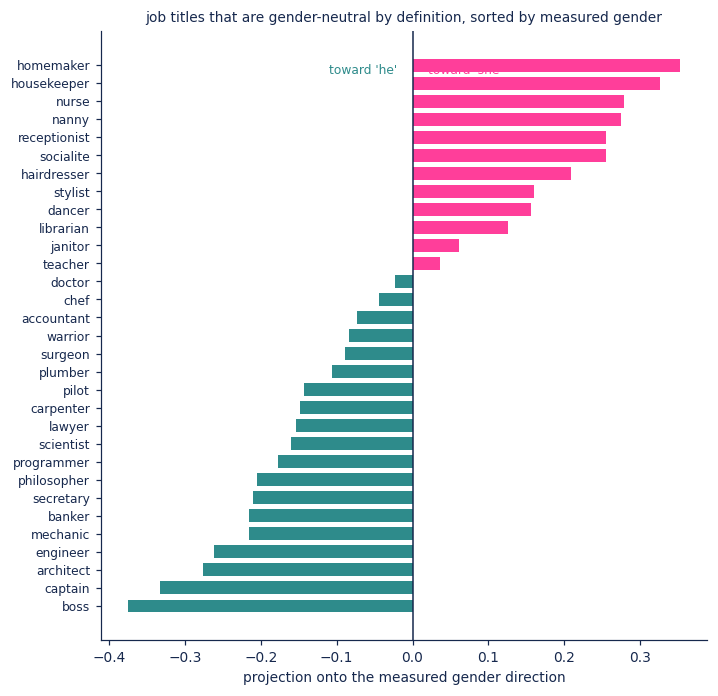

In [22]:
PROFESSIONS = ["nurse","homemaker","receptionist","librarian","hairdresser","nanny",
               "housekeeper","socialite","stylist","dancer","teacher","secretary",
               "doctor","engineer","programmer","architect","captain","philosopher",
               "boss","surgeon","carpenter","plumber","mechanic","scientist","lawyer",
               "accountant","chef","banker","pilot","janitor","warrior"]
PROFESSIONS = [w for w in PROFESSIONS if w in kv]
scores = {w: gender_score(w) for w in PROFESSIONS}
order = sorted(scores, key=scores.get)

fig, ax = plt.subplots(figsize=(6.6, 6.4))
vals = [scores[w] for w in order]
ax.barh(range(len(order)), vals,
        color=[TEAL if v < 0 else PINK for v in vals], height=0.72)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("projection onto the measured gender direction")
ax.text(0.02, len(order)-1.5, "toward 'she'", fontsize=8, color=PINK)
ax.text(-0.02, len(order)-1.5, "toward 'he'", fontsize=8, color=TEAL, ha="right")
ax.set_title("job titles that are gender-neutral by definition, sorted by measured gender",
             fontsize=9)
plt.tight_layout(); plt.show()

None of those words is gendered in English. There's no grammatical or semantic reason for `nurse` and `homemaker` to sit at one end and `boss` and `engineer` at the other. The model put them there because that's how they're used in Wikipedia and news text, and the training objective was to reproduce usage.

The analogy machinery makes this concrete in a way that's hard to look away from.

In [23]:
for pos, neg, label in [
    (["doctor","woman"],   ["man"], "doctor - man + woman"),
    (["programmer","woman"],["man"], "programmer - man + woman"),
    (["boss","woman"],     ["man"], "boss - man + woman"),
]:
    got = [w for w, _ in kv.most_similar(positive=pos, negative=neg, topn=4)]
    print(f"  {label:28s} -> {got}")

  doctor - man + woman         -> ['nurse', 'physician', 'doctors', 'patient']
  programmer - man + woman     -> ['educator', 'programmers', 'linguist', 'technician']
  boss - man + woman           -> ['bosses', 'girlfriend', 'boyfriend', 'colleague']


The same arithmetic that gave us `paris - france + italy = rome` gives us `doctor - man + woman = nurse`. It isn't a bug in the analogy code. It's the same mechanism reading out the same geometry, and the geometry says that the female-coded version of a doctor is a nurse.

Whether this matters depends entirely on what the vectors feed into. If they're the first layer of a résumé screener, a search ranker, or a recommendation system, this isn't an abstract concern. Static word embeddings sat underneath a great deal of production NLP for most of a decade, and they're still under plenty of retrieval systems today.

We can also put a single number on it. WEAT, the Word Embedding Association Test from Caliskan et al. (2017), measures how differentially two sets of target words associate with two sets of attribute words, and reports it as an effect size. The paper's headline finding was that these tests recover the same associations that the Implicit Association Test finds in humans.

In [24]:
MALE   = ["male","man","boy","brother","he","him","his","son"]
FEMALE = ["female","woman","girl","sister","she","her","hers","daughter"]
CAREER = ["executive","management","professional","corporation","salary",
          "office","business","career"]
FAMILY = ["home","parents","children","family","cousins","marriage",
          "wedding","relatives"]

def cos(a, b):
    return float(unit(a) @ unit(b))

def association(w, A, B, lookup):
    return (np.mean([cos(lookup(w), lookup(a)) for a in A])
            - np.mean([cos(lookup(w), lookup(b)) for b in B]))

def weat(X, Y, A, B, lookup):
    """Effect size: how differently X and Y associate with A vs B."""
    sx = [association(w, A, B, lookup) for w in X]
    sy = [association(w, A, B, lookup) for w in Y]
    return (np.mean(sx) - np.mean(sy)) / np.std(sx + sy)

original = lambda w: kv[w].astype(np.float64)
d_before = weat(CAREER, FAMILY, MALE, FEMALE, original)
print(f"WEAT effect size, career vs family against male vs female: d = {d_before:.2f}")
print("\nFor reference, Cohen conventionally calls 0.2 small, 0.5 medium and 0.8 large.")

WEAT effect size, career vs family against male vs female: d = 1.58

For reference, Cohen conventionally calls 0.2 small, 0.5 medium and 0.8 large.


## Can we just subtract it out?

This is the obvious engineering response, and it's what the field tried first. We measured the bias as a direction. Directions can be projected away. So take every word that ought to be gender-neutral and remove its component along `g`.

Bolukbasi et al. called this hard debiasing, and it has two steps.

**Neutralize.** For every word that isn't inherently gendered, subtract its projection onto `g`. Formally $w' = w - (w \cdot g)\,g$. After this the word sits exactly on the hyperplane perpendicular to `g`, with a gender score of zero.

**Equalize.** Take pairs that genuinely are gendered, like `man` and `woman`, and reposition them so they're exactly equidistant from every neutralised word. Without this step, `nurse` might end up at zero on the gender axis but still be nearer `woman` than `man` for unrelated reasons, and the neutralisation would look like it worked while changing nothing that matters.

We need a list of words to protect. In the original work this was a hand-built list of a few hundred genuinely gendered terms, and the fact that it has to be hand-built is our first hint that something is off.

In [25]:
N_VOCAB = 50_000
vwords = kv.index_to_key[:N_VOCAB]
vidx = {w: i for i, w in enumerate(vwords)}
E_orig = np.array([kv[w] for w in vwords], dtype=np.float64)
E_orig /= np.linalg.norm(E_orig, axis=1, keepdims=True)

GENDER_SPECIFIC = set("""he she him her his hers man woman men women boy girl boys girls
male female father mother son daughter brother sister uncle aunt nephew niece husband wife
mr mrs ms sir madam king queen prince princess himself herself gentleman lady guy gal
john mary sons daughters fathers mothers brothers sisters ladies gentlemen males females
grandmother grandfather widow widower bride groom waitress waiter actress nun monastery
businessman businesswoman congressman chairman spokesman spokeswoman fraternity sorority
schoolgirl schoolboy salesman councilman lad lads maiden""".split())

neutral = np.array([w not in GENDER_SPECIFIC for w in vwords])
print(f"{neutral.sum():,} of {N_VOCAB:,} words treated as gender-neutral "
      f"({(~neutral).sum()} protected)")

# --- neutralize
E_debiased = E_orig.copy()
E_debiased[neutral] = E_orig[neutral] - np.outer(E_orig[neutral] @ g, g)
E_debiased /= np.linalg.norm(E_debiased, axis=1, keepdims=True)

# --- equalize
EQUALIZE = [("man","woman"), ("he","she"), ("boy","girl"), ("father","mother"),
            ("son","daughter"), ("king","queen"), ("brother","sister"),
            ("uncle","aunt"), ("husband","wife")]
for a, b in EQUALIZE:
    if a not in vidx or b not in vidx:
        continue
    ia, ib = vidx[a], vidx[b]
    mu = (E_orig[ia] + E_orig[ib]) / 2
    nu = mu - (mu @ g) * g                      # the shared, non-gender part
    scale = np.sqrt(max(1 - nu @ nu, 0))        # what is left goes entirely into g
    for i in (ia, ib):
        sign = np.sign((E_orig[i] - E_orig[ib if i == ia else ia]) @ g)
        E_debiased[i] = unit(nu + sign * scale * g)

print("\nprojection onto g, before and after neutralize:")
for w in ["nurse","homemaker","engineer","programmer","boss"]:
    i = vidx[w]
    print(f"  {w:11s} {E_orig[i] @ g:+.3f}  ->  {E_debiased[i] @ g:+.3f}")

print("\nequalize check, distance from a pair to a neutral word:")
for a, b, n in [("man","woman","nurse"), ("man","woman","engineer")]:
    ia, ib, i_n = vidx[a], vidx[b], vidx[n]
    print(f"  before  cos({a},{n}) = {cos(E_orig[ia], E_orig[i_n]):.3f}   "
          f"cos({b},{n}) = {cos(E_orig[ib], E_orig[i_n]):.3f}")
    print(f"  after   cos({a},{n}) = {cos(E_debiased[ia], E_debiased[i_n]):.3f}   "
          f"cos({b},{n}) = {cos(E_debiased[ib], E_debiased[i_n]):.3f}")

49,919 of 50,000 words treated as gender-neutral (81 protected)

projection onto g, before and after neutralize:
  nurse       +0.279  ->  +0.000
  homemaker   +0.352  ->  +0.000
  engineer    -0.262  ->  -0.000
  programmer  -0.177  ->  -0.000
  boss        -0.375  ->  -0.000

equalize check, distance from a pair to a neutral word:
  before  cos(man,nurse) = 0.456   cos(woman,nurse) = 0.614
  after   cos(man,nurse) = 0.550   cos(woman,nurse) = 0.550
  before  cos(man,engineer) = 0.430   cos(woman,engineer) = 0.334
  after   cos(man,engineer) = 0.403   cos(woman,engineer) = 0.403


It worked, by its own definition. Every neutral word now has a gender projection of exactly zero, and the gendered pairs are precisely equidistant from them. The linear algebra did what we asked.

Now let us check the metric we were worried about in the first place.

In [26]:
debiased = lambda w: E_debiased[vidx[w]]
d_after = weat(CAREER, FAMILY, MALE, FEMALE, debiased)
print(f"WEAT effect size before debiasing: d = {d_before:.2f}")
print(f"WEAT effect size after  debiasing: d = {d_after:.2f}")
print(f"\nA {(1 - d_after/d_before):.0%} reduction. Ship it?")

WEAT effect size before debiasing: d = 1.58
WEAT effect size after  debiasing: d = 0.45

A 72% reduction. Ship it?


## Why doesn't that work?

Because we removed the bias from the measurement, not from the space. It's a tricky one.

The projection we subtracted is linear. It acts on the whole space globally. But word meaning isn't distributed evenly across the space; it's dense locally in clusters. The debiasing operation acts as a translation, shifting everything equally, but it doesn't change relative distances within those clusters.

In [27]:
def analogy(space, positive, negative, k=4):
    v = sum(space[vidx[w]] for w in positive) - sum(space[vidx[w]] for w in negative)
    sims = space @ unit(v)
    for w in positive + negative:
        sims[vidx[w]] = -9
    return [vwords[i] for i in np.argsort(-sims)[:k]]

for pos, neg, label in [(["doctor","woman"], ["man"], "doctor - man + woman"),
                        (["boss","woman"],   ["man"], "boss - man + woman")]:
    print(f"  {label}")
    print(f"    original : {analogy(E_orig,     pos, neg)}")
    print(f"    debiased : {analogy(E_debiased, pos, neg)}")
    print()

  doctor - man + woman
    original : ['nurse', 'physician', 'doctors', 'patient']
    debiased : ['nurse', 'mother', 'physician', 'sister']

  boss - man + woman
    original : ['bosses', 'girlfriend', 'boyfriend', 'colleague']
    debiased : ['bosses', 'sister', 'waitress', 'wife']



`nurse` is still the first answer. We zeroed out the gender component of both `doctor` and `nurse`, we made `man` and `woman` exactly symmetric, and the analogy returns the same word it did before. The association was never living in that one direction.

### Test two: a classifier can still read the old bias off the new vectors

If the bias were genuinely gone, then nothing in a debiased vector should predict what its bias used to be. So label the 500 most male-biased and 500 most female-biased words by their **original** projection, throw away the originals, and ask a linear classifier to recover those labels from the **debiased** vectors alone.

In [28]:
bias_before = E_orig @ g
candidates = np.array([i for i in range(len(vwords))
                       if neutral[i] and vwords[i].isalpha() and len(vwords[i]) > 2])
ranked = candidates[np.argsort(bias_before[candidates])]
he_side, she_side = ranked[:500], ranked[-500:]

print("most he-biased (originally):", [vwords[i] for i in he_side[:8]])
print("most she-biased (originally):", [vwords[i] for i in she_side[-8:]])

X = np.vstack([E_debiased[he_side], E_debiased[she_side]])
y = np.array([0]*500 + [1]*500)
acc = cross_val_score(LinearSVC(max_iter=5000), X, y, cv=5).mean()

print(f"\n5-fold accuracy predicting original bias from DEBIASED vectors: {acc:.1%}")
print("Chance is 50%. The information we supposedly deleted is still fully present.")

most he-biased (originally): ['defensive', 'gundy', 'chiefs', 'tackle', 'nfl', 'yawar', 'successor', 'sacked']
most she-biased (originally): ['olga', 'emilie', 'kristina', 'femininity', 'uterus', 'breastfeeding', 'rhoda', 'irina']

5-fold accuracy predicting original bias from DEBIASED vectors: 90.6%
Chance is 50%. The information we supposedly deleted is still fully present.


### Test three: the neighbourhoods are unchanged

This is the one that settles it. Bias in a deployed system rarely shows up as a projection onto a hand-picked axis. It shows up as which items get retrieved, which résumés cluster together, which words a nearest-neighbour lookup returns. So measure that directly: for each word, what fraction of its hundred nearest neighbours were originally female-biased?

fraction of the 100 nearest neighbours that were originally she-biased:

  word           original  debiased
  nurse              0.71      0.46
  receptionist       0.82      0.61
  homemaker          0.94      0.68
  engineer           0.03      0.14
  programmer         0.12      0.22
  plumber            0.42      0.54


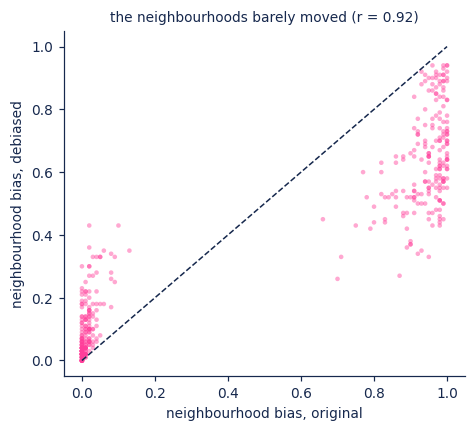

correlation between original and debiased neighbourhood bias: r = 0.916


In [29]:
def neighbour_bias(space, i, k=100):
    """Of this word's k nearest neighbours, what fraction were originally she-biased?"""
    sims = space @ space[i]
    top = np.argpartition(-sims, k + 1)[:k + 1]
    top = top[top != i][:k]
    return float((bias_before[top] > 0).mean())

print("fraction of the 100 nearest neighbours that were originally she-biased:\n")
print(f"  {'word':13s} {'original':>9s} {'debiased':>9s}")
for w in ["nurse", "receptionist", "homemaker", "engineer", "programmer", "plumber"]:
    i = vidx[w]
    print(f"  {w:13s} {neighbour_bias(E_orig, i):>9.2f} {neighbour_bias(E_debiased, i):>9.2f}")

sample = np.concatenate([he_side[:200], she_side[-200:]])
nb_before = np.array([neighbour_bias(E_orig,     i) for i in sample])
nb_after  = np.array([neighbour_bias(E_debiased, i) for i in sample])
r = np.corrcoef(nb_before, nb_after)[0, 1]

fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.scatter(nb_before, nb_after, s=9, alpha=0.45, color=PINK, edgecolors="none")
ax.plot([0, 1], [0, 1], color=INK, ls="--", lw=1)
ax.set_xlabel("neighbourhood bias, original"); ax.set_ylabel("neighbourhood bias, debiased")
ax.set_title(f"the neighbourhoods barely moved (r = {r:.2f})", fontsize=9)
plt.tight_layout(); plt.show()

print(f"correlation between original and debiased neighbourhood bias: r = {r:.3f}")

A correlation of that size means the debiasing did essentially nothing to the structure a real system would actually consume. `homemaker` still sits in an overwhelmingly female-coded neighbourhood after the fix, and `engineer` in an overwhelmingly male-coded one. Every point moved a little toward the middle and almost nothing changed rank. We adjusted one coordinate and left the map alone.

So what actually went wrong? Three things, and they generalise well beyond gender.

- **We debiased against a definition, not against a phenomenon.** The measurement was "projection onto `g`". The optimiser, in effect, minimised exactly that and nothing else. This is Goodhart's law with linear algebra, and you will meet it every time you turn a fairness concern into a single scalar and then optimise it.
- **The bias was never one-dimensional.** A 100-dimensional space has room for many correlated encodings of the same social pattern. Removing one leaves the rest, and the rest is enough to reconstruct the first.
- **The protected-word list is the whole problem in miniature.** Somebody had to decide that `nurse` is neutral and `queen` is not. That's the same hand-annotation task we abandoned back in the hand-built-features section, for the same reasons, and it doesn't get easier at scale or across languages.

None of which means the situation is hopeless, and it's worth being clear about that rather than ending on a shrug. What it means is that post-hoc geometric surgery on a finished embedding is the wrong intervention. The approaches with better evidence behind them act earlier or measure later: curating and documenting training data, measuring bias at the level of the downstream task rather than the representation, using counterfactual data augmentation during training, and adversarial objectives that penalise a discriminator's ability to recover the attribute rather than penalising one direction. All of those are harder than one projection, which is precisely why the projection was attractive.

And there's a broader point that survives the specific example. An embedding is a compression of its training corpus. It can't represent distinctions the corpus doesn't make, and it will faithfully reproduce the ones the corpus does make, including the ones nobody intended to teach it. The geometry that gives you `paris - france + italy = rome` for free is the same geometry that gives you `doctor - man + woman = nurse` for free. You don't get to keep one and delete the other by projection, because they're the same mechanism.

# Part 4: The Systems Reality (How Embeddings Shape Infrastructure)

## Connecting the dots: why any of this touches infrastructure

It would be easy to file embeddings under "modelling" and move on. They're the first layer, they're conceptually simple, and the interesting compute is obviously further down the stack. That instinct is wrong in a specific and expensive way, because the embedding table is the one part of a model that behaves nothing like the rest of it.

Here is the concrete version, in four parts.

### It's a large fraction of your parameters and none of your FLOPs

The table is `vocab_size x d_model`. Nothing about that scales with depth, so as models get wider the table grows with them, and vocabularies have been growing too. Many architectures also keep a separate output projection of the same shape, which doubles it unless you tie the two together.

In [30]:
print(f"{'vocab':>9s} {'d_model':>8s} {'input table':>13s} {'+ output head':>15s} {'bf16 bytes':>12s}")
for vocab, d in [(32_000, 4096), (50_257, 768), (128_256, 4096), (256_000, 8192)]:
    one = vocab * d
    print(f"{vocab:>9,} {d:>8,} {one/1e6:>10.0f} M {2*one/1e6:>13.0f} M "
          f"{2*one*2/1e9:>10.2f} GB")

print("\nTying the input and output matrices halves that, at some cost in quality.")
print("It is one of the cheapest parameter savings available and worth knowing about.")

    vocab  d_model   input table   + output head   bf16 bytes
   32,000    4,096        131 M           262 M       0.52 GB
   50,257      768         39 M            77 M       0.15 GB
  128,256    4,096        525 M          1051 M       2.10 GB
  256,000    8,192       2097 M          4194 M       8.39 GB

Tying the input and output matrices halves that, at some cost in quality.
It is one of the cheapest parameter savings available and worth knowing about.


Now the flip side. A lookup is a gather. It reads rows out of memory and does no arithmetic at all.

In [31]:
batch, seq, d, vocab = 8, 2048, 4096, 128_256
tokens = batch * seq

lookup_bytes = tokens * d * 2                 # bf16 rows read out
lookup_flops = 0                              # a gather multiplies nothing

# for comparison, one dense projection of the same activations
proj_bytes = (tokens * d + d * d) * 2
proj_flops = 2 * tokens * d * d

print(f"for a {batch} x {seq} batch at d_model={d}:\n")
print(f"  embedding lookup   {lookup_bytes/1e6:8.1f} MB moved   {lookup_flops:>14,} FLOPs")
print(f"  one d x d projection {proj_bytes/1e6:6.1f} MB moved   {proj_flops/1e9:>12.1f} GFLOPs")
print(f"\n  arithmetic intensity of the lookup:     {lookup_flops} FLOPs per byte")
print(f"  arithmetic intensity of the projection: {proj_flops/proj_bytes:.0f} FLOPs per byte")

for a 8 x 2048 batch at d_model=4096:

  embedding lookup      134.2 MB moved                0 FLOPs
  one d x d projection  167.8 MB moved          549.8 GFLOPs

  arithmetic intensity of the lookup:     0 FLOPs per byte
  arithmetic intensity of the projection: 3277 FLOPs per byte


Zero FLOPs per byte means the lookup can never be compute-bound. It sits at the far left of the roofline, pinned against memory bandwidth, and no amount of matmul throughput helps it. If you try to run this pattern on standard matrix units, you'll see a quite noticeable performance hit, because accelerators are built to keep systolic arrays fed, and this is the one operation in the model that has nothing to feed them.

That mismatch is why dedicated hardware for it exists. Google's TPUs from v4 onward ship SparseCore, a unit specifically for embedding lookups and the scatter-gather traffic around them, precisely because running that pattern on the matrix units wastes them. On the GPU side, libraries like NVIDIA's Merlin and PyTorch's TorchRec exist for the same reason.

In [32]:
def touched(vocab, tokens):
    """Expected distinct rows hit, assuming roughly uniform IDs. A coupon-collector bound."""
    return vocab * (1 - np.exp(-tokens / vocab))

print(f"{'setting':>26s} {'vocab':>10s} {'tokens':>9s} {'rows hit':>10s} "
      f"{'dense grad':>11s} {'sparse':>9s} {'saving':>8s}")
for label, vocab, d, tokens in [
        ("LLM, 8 x 2048 seq",        128_256, 4096, 8 * 2048),
        ("LLM, 1 x 512 seq",         128_256, 4096, 512),
        ("recommender, 8k batch", 50_000_000,  128, 8192)]:
    hit = touched(vocab, tokens)
    dense, sparse = vocab * d * 4, hit * d * 4
    print(f"{label:>26s} {vocab:>10,} {tokens:>9,} {hit:>10,.0f} "
          f"{dense/1e9:>9.1f} GB {sparse/1e6:>7.1f} MB {dense/sparse:>7.0f}x")

vocab, d = 128_256, 4096
table = vocab * d * 4
print(f"\nand the optimizer state for that LLM table, if it is dense:")
print(f"  fp32 weights {table/1e9:.2f} GB + Adam m {table/1e9:.2f} GB "
      f"+ Adam v {table/1e9:.2f} GB = {3*table/1e9:.2f} GB")

                   setting      vocab    tokens   rows hit  dense grad    sparse   saving
         LLM, 8 x 2048 seq    128,256    16,384     15,381       2.1 GB   252.0 MB       8x
          LLM, 1 x 512 seq    128,256       512        511       2.1 GB     8.4 MB     251x
     recommender, 8k batch 50,000,000     8,192      8,191      25.6 GB     4.2 MB    6104x

and the optimizer state for that LLM table, if it is dense:
  fp32 weights 2.10 GB + Adam m 2.10 GB + Adam v 2.10 GB = 6.30 GB


Even in the LLM case the saving is real. In the recommender case it's the difference between feasible and impossible, which is why embedding layers get sparse optimizer paths, or Adagrad rather than Adam, or are hoisted out into a dedicated parameter server. It's also worth checking rather than assuming: a dense gradient for the table is a quiet way to lose most of a memory budget, and the aggregate profile won't point at it.

### It shards differently from everything else

The rest of the model shards along familiar lines: data parallel over the batch, tensor parallel over hidden dimensions, pipeline parallel over layers. The embedding table doesn't fit any of them cleanly, because it's one enormous parameter that every device needs random access to.

The two standard options each cost you something:

- **Row-wise (table-parallel).** Split the vocabulary across devices. Each device holds a slice of rows and can only serve lookups for its own slice, so every step needs an all-to-all: send each token ID to whichever device owns it, then gather the resulting rows back. Communication scales with batch size.
- **Column-wise.** Every device holds all rows but only a slice of `d_model`. Lookups are local, but every device now stores `vocab_size` rows, so the memory saving is only in the width.

Recommender systems make this the dominant cost rather than a footnote. A production ranking model can carry hundreds of gigabytes or terabytes of embedding tables against a comparatively tiny dense network, and its training throughput is set almost entirely by how well the all-to-all is overlapped with compute. If you have ever wondered why recommender training looks nothing like LLM training on a profile, this is why.

### At serving time the table becomes the database

Everything above is training. On the retrieval side, embeddings stop being a layer and become storage, and the arithmetic is unforgiving.

In [33]:
print(f"{'vectors':>12s} {'dim':>6s} {'fp32':>10s} {'int8':>10s} {'PQ (64B)':>10s}")
for n in [1_000_000, 100_000_000, 1_000_000_000]:
    for dim in [768, 1536]:
        f32, i8, pq = n*dim*4, n*dim*1, n*64
        print(f"{n:>12,} {dim:>6d} {f32/1e9:>8.1f} GB {i8/1e9:>8.1f} GB {pq/1e9:>8.1f} GB")

print("\nAn HNSW index adds graph edges on top, often another 30 to 50 percent.")
print("This is the whole reason quantization and product quantization exist in vector")
print("databases, and why Matryoshka embeddings, which are trained so that the first")
print("k dimensions are usable on their own, are attractive: you truncate instead of")
print("re-embedding when you want to trade recall for memory.")

     vectors    dim       fp32       int8   PQ (64B)
   1,000,000    768      3.1 GB      0.8 GB      0.1 GB
   1,000,000   1536      6.1 GB      1.5 GB      0.1 GB
 100,000,000    768    307.2 GB     76.8 GB      6.4 GB
 100,000,000   1536    614.4 GB    153.6 GB      6.4 GB
1,000,000,000    768   3072.0 GB    768.0 GB     64.0 GB
1,000,000,000   1536   6144.0 GB   1536.0 GB     64.0 GB

An HNSW index adds graph edges on top, often another 30 to 50 percent.
This is the whole reason quantization and product quantization exist in vector
databases, and why Matryoshka embeddings, which are trained so that the first
k dimensions are usable on their own, are attractive: you truncate instead of
re-embedding when you want to trade recall for memory.


So the practical checklist, if you're the person who has to make these decisions:

- Vocabulary size and `d_model` are a joint memory decision, not two independent modelling ones, and tying the output head is the first lever to reach for.
- Profile the embedding layer separately from the rest of the model. It's a good habit to be getting into. It'll be bandwidth-bound and the aggregate numbers will hide it.
- Check whether your framework is materialising dense gradients for the table. It's a common and quiet way to lose most of your memory budget.
- Budget the all-to-all before you pick a sharding strategy, especially if the tables are large relative to the dense network.
- On the serving side, decide your quantization strategy before you build the index, because rebuilding a billion-vector index isn't a thing you want to do twice.

And the thread running through all of it: an embedding table is a memory system with a lookup interface, and it happens to be differentiable. Treating it as just another layer is what leads to the surprises.

## Where to next?

We now have a fixed vector per token, learned from context, carrying real structure and some structure we did not ask for. The obvious remaining problem is the one we flagged twice: it's the same vector every time. `bank` gets one row whether there's a river in the sentence or not, and `python` averages a snake with a language. Fixing that's what self-attention does, and there's a notebook in this series that builds it up the same way this one did, one repair at a time.

After that comes positional encoding, which handles the other thing this representation can't see, namely word order.

Meanwhile, the sources behind this notebook:

- [Efficient Estimation of Word Representations in Vector Space](https://arxiv.org/abs/1301.3781) (Mikolov, Chen, Corrado, Dean, 2013)
- [Distributed Representations of Words and Phrases and their Compositionality](https://arxiv.org/abs/1310.4546) (Mikolov et al., 2013), which is where negative sampling and subsampling come from
- [GloVe: Global Vectors for Word Representation](https://nlp.stanford.edu/pubs/glove.pdf) (Pennington, Socher, Manning, EMNLP 2014)
- [Neural Word Embedding as Implicit Matrix Factorization](https://papers.nips.cc/paper/2014/hash/feab05aa91086b7a8010f8e6330ef009-Abstract.html) (Levy and Goldberg, NeurIPS 2014), the paper connecting the two routes we took
- [Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings](https://arxiv.org/abs/1607.06520) (Bolukbasi, Chang, Zou, Saligrama, Kalai, 2016)
- [Semantics derived automatically from language corpora contain human-like biases](https://www.science.org/doi/10.1126/science.aal4230) (Caliskan, Bryson, Narayanan, Science 2017), the WEAT paper
- [Lipstick on a Pig: Debiasing Methods Cover up Systematic Gender Biases in Word Embeddings](https://arxiv.org/abs/1903.03862) (Gonen and Goldberg, NAACL 2019)
- [Matryoshka Representation Learning](https://arxiv.org/abs/2205.13147) (Kusupati et al., NeurIPS 2022)
- [Speech and Language Processing, Chapter 6: Vector Semantics and Embeddings](https://web.stanford.edu/~jurafsky/slp3/6.pdf) (Jurafsky and Martin), the best free textbook treatment of vector semantics